In [106]:
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.preprocessing import StandardScaler

In [107]:
data = pd.read_csv("../data/curated/merged_data.csv")
print(list(data.columns))

['property type', 'beds', 'baths', 'parking', 'weekly rent amount', 'postcode', 'distance primary school', 'distance secondary school', 'is closest school good', 'closest university campus', 'distance university campus', 'closest hospital', 'distance to closest hospital', 'offence count 2023', 'estimated resident population (no.) 2011', 'total dwellings (no.) 2017', 'median equivalised total household income (weekly) ($) 2011', 'median weekly household rental payment ($) 2011', 'average family size (no. of persons) 2011', 'estimated resident population (no.) 2016', 'total dwellings (no.) 2019', 'median equivalised total household income (weekly) ($) 2016', 'median weekly household rental payment ($) 2016', 'average family size (no. of persons) 2016', 'estimated resident population (no.) 2021', 'total dwellings (no.) 2021', 'median equivalised total household income (weekly) ($) 2021', 'median weekly household rental payment ($) 2021', 'average family size (no. of persons) 2021', 'total

In [108]:
data = data.drop(["closest university campus", "closest hospital", "postcode", "closest university campus"], axis=1)
print(len(data))
data = data[data["weekly rent amount"] <= 2000]
data["weekly rent amount"] = np.log(data["weekly rent amount"])
print(len(data))

11345
11279


In [109]:
def predict_2023_value(y_values, col_name, x_values = [0,5,10], predict_val = 12): 
    """ 
    Function predicts 2023 value of variable given past data. Assumes linear relationship.
    default value of x_value 0, 5, 10 represents 2011, 2016, 2021. 
    default value of predict_val represents 2023
    """
    # 0, 5, 10 represents 2011, 2016, 2021
    print(y_values)
    print(col_name)
    model = LinearRegression()
    x_values = np.array(x_values).reshape(-1,1)
    y_values = np.array(y_values).reshape(-1,1)
    model.fit(x_values, y_values)
    # 12 represents 2023
    predict_2023 = model.predict(np.array(predict_val).reshape(-1,1))
    return pd.Series({col_name: predict_2023[0][0]})

In [110]:

# predict median equivalised total household income (weekly) ($) 2023
median_income_2023_column = data.apply(lambda x:
    predict_2023_value([x["median equivalised total household income (weekly) ($) 2011"], 
     x["median equivalised total household income (weekly) ($) 2016"],
     x["median equivalised total household income (weekly) ($) 2021"]], 
    "predicted median equivalised total household income (weekly) ($) 2023"), axis=1)

data = pd.concat([data, median_income_2023_column], axis=1)
data[["median equivalised total household income (weekly) ($) 2011", 
     "median equivalised total household income (weekly) ($) 2016",
     "median equivalised total household income (weekly) ($) 2021", 
     "predicted median equivalised total household income (weekly) ($) 2023"]]

data = data.drop(["median equivalised total household income (weekly) ($) 2011", 
     "median equivalised total household income (weekly) ($) 2016",
     "median equivalised total household income (weekly) ($) 2021"], axis=1)

[1089.0, 1265.6666666666667, 1495.0]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[628.0, 761.0, 931.0]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[509.0, 560.0, 637.0]
predicted median equivalised total household income (weekly) ($) 2023
[575.25, 651.25, 812.75]
predicted median equivalised total household income (weekly) ($) 2023
[697.6, 758.2, 988.8]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalised total household income (weekly) ($) 2023
[1201.0, 1361.0, 1578.5]
predicted median equivalised total household income (weekly) ($) 2023
[729.5, 859.0, 1116.25]
predicted median equivalise

In [111]:
# median weekly household rental payment ($) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["median weekly household rental payment ($) 2011"], 
     x["median weekly household rental payment ($) 2016"],
     x["median weekly household rental payment ($) 2021"]], 
    "predicted median weekly household rental payment ($) 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["median weekly household rental payment ($) 2011", 
     "median weekly household rental payment ($) 2016",
     "median weekly household rental payment ($) 2021", 
     "predicted median weekly household rental payment ($) 2023"]]


data = data.drop(["median weekly household rental payment ($) 2011", 
     "median weekly household rental payment ($) 2016",
     "median weekly household rental payment ($) 2021"], axis=1)



[367.0, 420.3333333333333, 466.0]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[271.0, 330.0, 405.0]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[150.0, 180.0, 215.0]
predicted median weekly household rental payment ($) 2023
[255.5, 300.5, 334.5]
predicted median weekly household rental payment ($) 2023
[309.6, 334.4, 372.8]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[360.0, 391.0, 406.5]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[269.25, 326.25, 381.25]
predicted median weekly household rental payment ($) 2023
[240.0, 28

In [112]:
# predict average family size (no. of persons) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["average family size (no. of persons) 2011"], 
     x["average family size (no. of persons) 2016"],
     x["average family size (no. of persons) 2021"]], 
    "predicted average family size (no. of persons) 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["average family size (no. of persons) 2011", 
     "average family size (no. of persons) 2016",
     "average family size (no. of persons) 2021", 
     "predicted average family size (no. of persons) 2023"]]


data = data.drop(["average family size (no. of persons) 2011", 
     "average family size (no. of persons) 2016",
     "average family size (no. of persons) 2021"], axis=1)


[3.1333333333333333, 3.1333333333333333, 3.033333333333333]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.7, 2.7, 2.7]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.8, 2.8, 2.8]
predicted average family size (no. of persons) 2023
[3.025, 3.025, 3.025]
predicted average family size (no. of persons) 2023
[3.04, 3.04, 2.96]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.45, 2.45, 2.5]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[2.925, 2.975, 3.0]
predicted average family size (no. of persons) 2023
[3.0, 2.9, 2.9]
predicted average family size (no. of persons) 2023
[3.1333333333333333, 3.16666666666666

In [113]:
# predict median weekly household rental payment ($) 2023
weekly_rent_2023_column = data.apply(lambda x:
    predict_2023_value([x["employment ratio 2011"], 
     x["employment ratio 2016"],
     x["employment ratio 2021"]], 
    "predicted employment ratio 2023"), axis=1)

data = pd.concat([data, weekly_rent_2023_column], axis=1)

data[["employment ratio 2011", 
     "employment ratio 2016",
     "employment ratio 2021", 
     "predicted employment ratio 2023"]]


data = data.drop(["employment ratio 2011", 
     "employment ratio 2016",
     "employment ratio 2021"], axis=1)

[0.9559454742700816, 0.9464455426724956, 0.9557909279300024]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.9477260846837428, 0.9499287604315082, 0.96588274263001]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.8778321551567881, 0.8559662899827619, 0.8905660377358491]
predicted employment ratio 2023
[0.9007145859604876, 0.8874827955344854, 0.9205526770293608]
predicted employment ratio 2023
[0.9270833333333334, 0.9057836644591613, 0.9342460070524788]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted employment ratio 2023
[0.9563015558107968, 0.9489363704819276, 0.9572294059137354]
predicted employment ratio 2023
[0.9526246472248354, 0.9422108866366872, 0.9598731245594604]
predicted e

In [114]:
# predict total dwellings (no.) 2017  2023
dwelling_2023_column = data.apply(lambda x:
    predict_2023_value([x["total dwellings (no.) 2017"], 
     x["total dwellings (no.) 2019"],
     x["total dwellings (no.) 2021"]], 
    "predicted total dwellings (no.) 2023", [0,2,4], 6), axis=1)

data = pd.concat([data, dwelling_2023_column], axis=1)

data[["total dwellings (no.) 2017", 
     "total dwellings (no.) 2019",
     "total dwellings (no.) 2021", 
     "predicted total dwellings (no.) 2023"]]


data = data.drop(["total dwellings (no.) 2017", 
     "total dwellings (no.) 2019",
     "total dwellings (no.) 2021"], axis=1)

[17239.0, 17551.0, 17800.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[8219.0, 8551.0, 8829.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[6945.0, 6961.0, 7010.0]
predicted total dwellings (no.) 2023
[23194.0, 23885.0, 24313.0]
predicted total dwellings (no.) 2023
[18968.0, 19363.0, 19908.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[20419.0, 20978.0, 21725.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[25222.0, 27051.0, 29407.0]
predicted total dwellings (no.) 2023
[10134.0, 10599.0, 10780.0]
predicted total dwellings (no.) 2023
[19833.0, 20217.0, 20457.0]
predicted total dwellings (no.) 2023
[19833.0, 20217.0, 20457.0]
predicted total dwellings (no.) 2023
[23656.0, 23927.0, 24272.0]
pre

In [115]:
print(list(data.columns))

['property type', 'beds', 'baths', 'parking', 'weekly rent amount', 'distance primary school', 'distance secondary school', 'is closest school good', 'distance university campus', 'distance to closest hospital', 'offence count 2023', 'estimated resident population (no.) 2011', 'estimated resident population (no.) 2016', 'estimated resident population (no.) 2021', 'total_supermarkets', 'major_supermarkets', 'city_centre', 'closest_city_centre', 'coastal', 'closest_cc_dist', 'dist_to_melb', 'predicted median equivalised total household income (weekly) ($) 2023', 'predicted median weekly household rental payment ($) 2023', 'predicted average family size (no. of persons) 2023', 'predicted employment ratio 2023', 'predicted total dwellings (no.) 2023']


In [116]:
data.isna().any()

property type                                                            False
beds                                                                     False
baths                                                                    False
parking                                                                  False
weekly rent amount                                                       False
distance primary school                                                  False
distance secondary school                                                False
is closest school good                                                   False
distance university campus                                               False
distance to closest hospital                                             False
offence count 2023                                                       False
estimated resident population (no.) 2011                                 False
estimated resident population (no.) 2016            

In [117]:
# drop columns with missing values
data = data.drop(["total_supermarkets", "major_supermarkets"], axis=1)

In [118]:
list(data.columns[data.isna().any()])

['city_centre',
 'closest_city_centre',
 'coastal',
 'closest_cc_dist',
 'dist_to_melb']

In [119]:
print(len(data))
data = data.dropna()
print(len(data))

11279
11169


In [120]:
data[data.isna().any(axis=1)]

,property type,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,...,city_centre,closest_city_centre,coastal,closest_cc_dist,dist_to_melb,predicted median equivalised total household income (weekly) ($) 2023,predicted median weekly household rental payment ($) 2023,predicted average family size (no. of persons) 2023,predicted employment ratio 2023,predicted total dwellings (no.) 2023


In [121]:
# ensure categorical variables behave as categorical variables
#data["postcode"] = data["postcode"].astype("category")

In [122]:
# data for linear regression before one-hot-encoding
data.to_csv("../data/curated/data_lin_reg_before_onehotencode.csv", index=False)

In [123]:
# one hot encode categorical variables


data = pd.get_dummies(data, columns=["property type", "closest_city_centre"])

#data = pd.get_dummies(data, columns=["postcode", "property type", "closest_city_centre"])

data

,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,offence count 2023,...,closest_city_centre_Horsham,closest_city_centre_Melbourne,closest_city_centre_Morwell,closest_city_centre_Sale,closest_city_centre_Shepparton,closest_city_centre_Swan Hill,closest_city_centre_Traralgon,closest_city_centre_Wangaratta,closest_city_centre_Warrnambool,closest_city_centre_Wodonga
0,1,2,6,4.787492,0.586504,2.491226,True,7.430317,2.104719,29.0,...,False,True,False,False,False,False,False,False,False,False
1,9,2,2,4.867534,1.372612,2.438191,False,0.675843,6.688022,121.0,...,False,False,False,False,False,False,False,False,False,False
2,1,1,0,4.941642,4.858273,3.301447,True,47.278807,10.766412,17.0,...,False,False,False,False,False,False,False,False,False,False
3,1,2,6,4.941642,1.114181,1.998214,False,1.502495,6.057051,121.0,...,False,False,False,False,False,False,False,False,False,False
4,1,4,3,5.010635,0.215009,1.989564,False,1.862509,5.472987,121.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11274,3,2,3,7.600902,2.810575,31.691494,False,187.540286,30.648511,2.0,...,False,False,False,True,False,False,False,False,False,False
11275,2,2,1,7.600902,0.992686,1.233583,False,0.636699,0.308229,115.0,...,False,True,False,False,False,False,False,False,False,False
11276,6,3,1,7.600902,0.666437,0.247490,False,0.831730,0.729823,70.0,...,False,True,False,False,False,False,False,False,False,False
11277,4,3,2,7.600902,0.496110,0.631375,False,1.570319,1.368946,42.0,...,False,True,False,False,False,False,False,False,False,False


# Linear Regression Model

In [124]:
data["city_centre"] = data["city_centre"].astype(bool)
data["coastal"] = data["coastal"].astype(bool)

In [125]:
y = data["weekly rent amount"]
X = data.drop(["weekly rent amount"], axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [126]:
type_dict = dict(data.dtypes)
print(str(type(type_dict["is closest school good"])))

def get_key_from_value(my_dict, search_value):
    # Iterate through the dictionary items
    for key, value in my_dict.items():
        if str(value) == search_value:
            return key  # Return the key if the value matches the search_value
    # If the search_value is not found, you can return a default value or raise an exception
    return None  # Return None (or raise an exception) if the search_value is not found

# Example dictionary
my_dict = {'apple': 1, 'banana': 2, 'cherry': 3, 'date': 2}

# Find the key for a specific value
search_value = "object"
key = get_key_from_value(type_dict, search_value)

if key is not None:
    print(f"The key for value {search_value} is: {key}")
else:
    print(f"Value {search_value} not found in the dictionary.")

<class 'numpy.dtype[bool_]'>
Value object not found in the dictionary.


In [127]:
data["city_centre"] = data["city_centre"].astype(bool)
data.dtypes
# Find the key for a specific value
search_value = "object"
key = get_key_from_value(type_dict, search_value)

if key is not None:
    print(f"The key for value {search_value} is: {key}")
else:
    print(f"Value {search_value} not found in the dictionary.")

Value object not found in the dictionary.


In [128]:
data = data.drop(["city_centre"], axis=1)

In [129]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [130]:
X_train_scaled

array([[ 0.33459485,  0.76549076,  0.61385334, ..., -0.07193702,
        -0.0920055 , -0.08757217],
       [ 1.28277279,  2.4128077 ,  0.61385334, ..., -0.07193702,
        -0.0920055 , -0.08757217],
       [-1.56176101, -0.88182618, -1.31435182, ..., -0.07193702,
        -0.0920055 , -0.08757217],
       ...,
       [ 0.33459485,  0.76549076,  0.61385334, ..., -0.07193702,
        -0.0920055 , -0.08757217],
       [-0.61358308,  0.76549076, -0.35024924, ..., -0.07193702,
        -0.0920055 , -0.08757217],
       [ 1.28277279,  0.76549076,  0.61385334, ..., -0.07193702,
        -0.0920055 , -0.08757217]])

In [131]:
print(dict(data.isna().any()))

{'beds': False, 'baths': False, 'parking': False, 'weekly rent amount': False, 'distance primary school': False, 'distance secondary school': False, 'is closest school good': False, 'distance university campus': False, 'distance to closest hospital': False, 'offence count 2023': False, 'estimated resident population (no.) 2011': False, 'estimated resident population (no.) 2016': False, 'estimated resident population (no.) 2021': False, 'coastal': False, 'closest_cc_dist': False, 'dist_to_melb': False, 'predicted median equivalised total household income (weekly) ($) 2023': False, 'predicted median weekly household rental payment ($) 2023': False, 'predicted average family size (no. of persons) 2023': False, 'predicted employment ratio 2023': False, 'predicted total dwellings (no.) 2023': False, 'property type_Acreage / Semi-Rural': False, 'property type_Apartment / Unit / Flat': False, 'property type_Duplex': False, 'property type_House': False, 'property type_New Apartments / Off the 

In [132]:
data[data.isnull().any(axis=1)]

,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,offence count 2023,...,closest_city_centre_Horsham,closest_city_centre_Melbourne,closest_city_centre_Morwell,closest_city_centre_Sale,closest_city_centre_Shepparton,closest_city_centre_Swan Hill,closest_city_centre_Traralgon,closest_city_centre_Wangaratta,closest_city_centre_Warrnambool,closest_city_centre_Wodonga


In [133]:
import xgboost as xgb
from sklearn.metrics import r2_score
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=70, learning_rate=0.1)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)


In [134]:
r2

0.7589245665457152

In [135]:
pred_true_val = pd.DataFrame({"y_test": y_test, "predictions": predictions})

In [136]:
pred_true_val["error"] = np.abs(pred_true_val["y_test"] - pred_true_val["predictions"])
pred_true_val

,y_test,predictions,error
3467,6.131226,6.192959,0.061733
3466,6.131226,6.143177,0.011951
2336,6.063785,6.108668,0.044883
5884,6.291569,6.150900,0.140669
1391,5.966147,6.066416,0.100270
...,...,...,...
4932,6.214608,6.220879,0.006271
2925,6.109248,6.172060,0.062812
6792,6.345636,6.308958,0.036678
6413,6.309918,6.232060,0.077858


In [137]:
from sklearn.metrics import mean_squared_error


# Calculate the mean squared error (MSE)
mse = mean_squared_error(y_test, predictions)

# Calculate the root mean squared error (RMSE)
rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Squared Error (MSE): 0.03037240261507566
Root Mean Squared Error (RMSE): 0.17427679884332184


In [138]:
booster = model.get_booster()
feature_scores = booster.get_score(importance_type='weight')
print("Feature Scores:", feature_scores)

Feature Scores: {'beds': 460.0, 'baths': 148.0, 'parking': 227.0, 'distance primary school': 404.0, 'distance secondary school': 333.0, 'is closest school good': 17.0, 'distance university campus': 290.0, 'distance to closest hospital': 310.0, 'offence count 2023': 94.0, 'estimated resident population (no.) 2011': 47.0, 'estimated resident population (no.) 2016': 11.0, 'estimated resident population (no.) 2021': 24.0, 'coastal': 9.0, 'closest_cc_dist': 202.0, 'dist_to_melb': 128.0, 'predicted median equivalised total household income (weekly) ($) 2023': 148.0, 'predicted median weekly household rental payment ($) 2023': 142.0, 'predicted average family size (no. of persons) 2023': 167.0, 'predicted employment ratio 2023': 82.0, 'predicted total dwellings (no.) 2023': 28.0, 'property type_Acreage / Semi-Rural': 13.0, 'property type_Apartment / Unit / Flat': 43.0, 'property type_House': 22.0, 'property type_New Apartments / Off the Plan': 6.0, 'property type_Retirement': 2.0, 'property t

In [139]:
pred_true_val.groupby("y_test")["error"].mean().reset_index()

,y_test,error
0,4.787492,1.651437
1,4.941642,0.570326
2,5.105945,0.291467
3,5.135798,0.652796
4,5.192957,0.539905
...,...,...
187,7.518064,0.401894
188,7.522941,0.375617
189,7.549609,0.304675
190,7.595890,0.415784


<AxesSubplot:xlabel='error', ylabel='Count'>

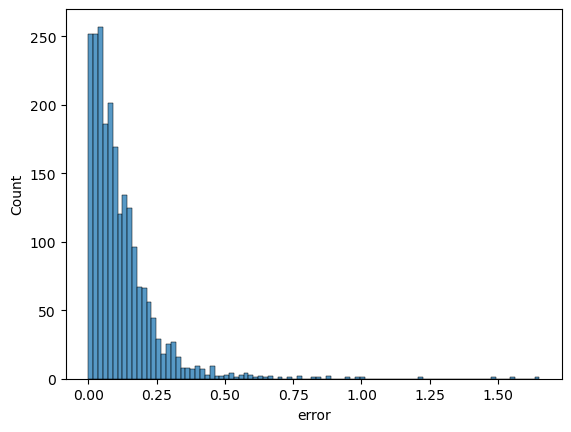

In [140]:
sns.histplot(pred_true_val["error"])

In [149]:
import pandas as pd

# Create a sample dataframe (replace this with your own dataset)
data = {
    'Feature1': [1.0, 2.0, 3.0, 4.0, 5.0],
    'Feature2': [2.0, 3.0, 4.0, 5.0, 6.0],
    'Feature3': [3.0, 4.0, 5.0, 6.0, 7.0],
    'Feature4': [4.0, 5.0, 6.0, 7.0, 8.0]
}

df = pd.DataFrame(data)

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Print the correlation matrix
print(correlation_matrix)

          Feature1  Feature2  Feature3  Feature4
Feature1       1.0       1.0       1.0       1.0
Feature2       1.0       1.0       1.0       1.0
Feature3       1.0       1.0       1.0       1.0
Feature4       1.0       1.0       1.0       1.0


In [141]:
average_error = pred_true_val.groupby("y_test")["error"].mean().reset_index()
average_error
max(average_error["error"])

1.6514368613439308

In [142]:
average_error[average_error["y_test"] == 2000]

,y_test,error


In [143]:
average_error["y_test"].max()

7.600902459542082

<AxesSubplot:xlabel='y_test', ylabel='Count'>

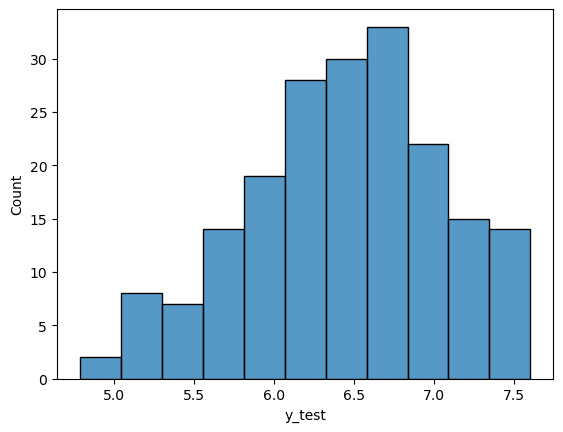

In [144]:
sns.histplot(average_error["y_test"])

Text(0, 0.5, 'Error Prediction')

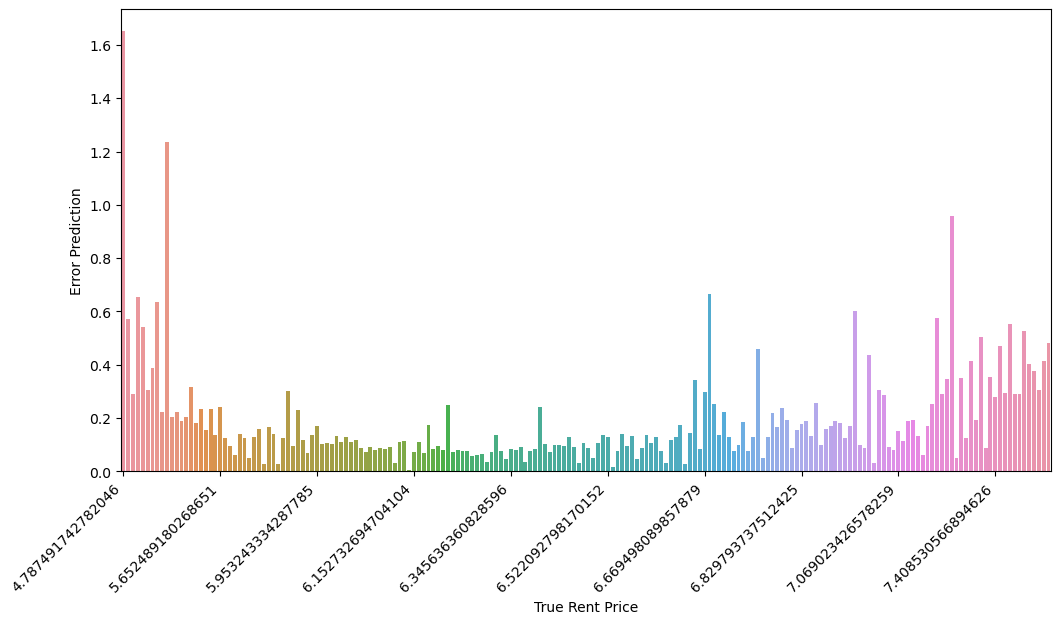

In [145]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x="y_test", y="error", data=average_error, ax=ax)
tick_interval = 20  # Show every 20th label
x_values = list(average_error["y_test"])
visible_indices = range(0, len(x_values), tick_interval) 
visible_ticks = [x_values[i] for i in visible_indices]
ax.set_xticks(visible_indices)
ax.set_xticklabels(visible_ticks, rotation=45, ha='right')  # Rotate and align the labels
ax.set_xlabel("True Rent Price")
ax.set_ylabel("Error Prediction")



<AxesSubplot:xlabel='weekly rent amount', ylabel='Count'>

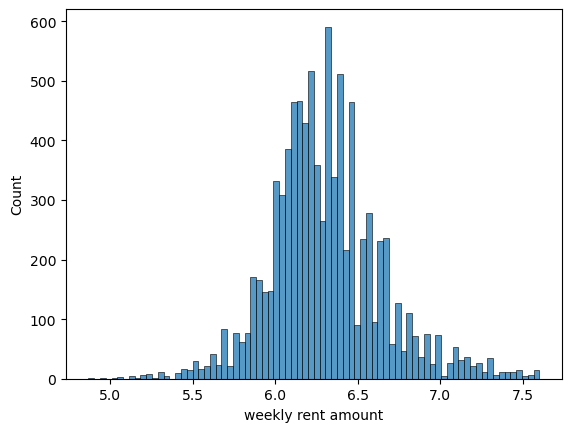

In [146]:
sns.histplot(y_train)

<AxesSubplot:xlabel='weekly rent amount', ylabel='Count'>

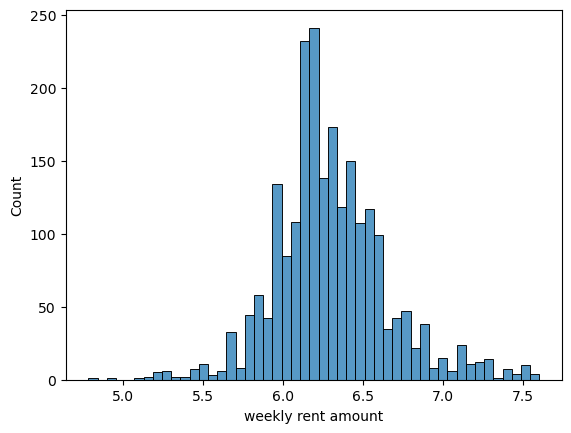

In [147]:
sns.histplot(y_test)

TypeError: 'type' object is not iterable

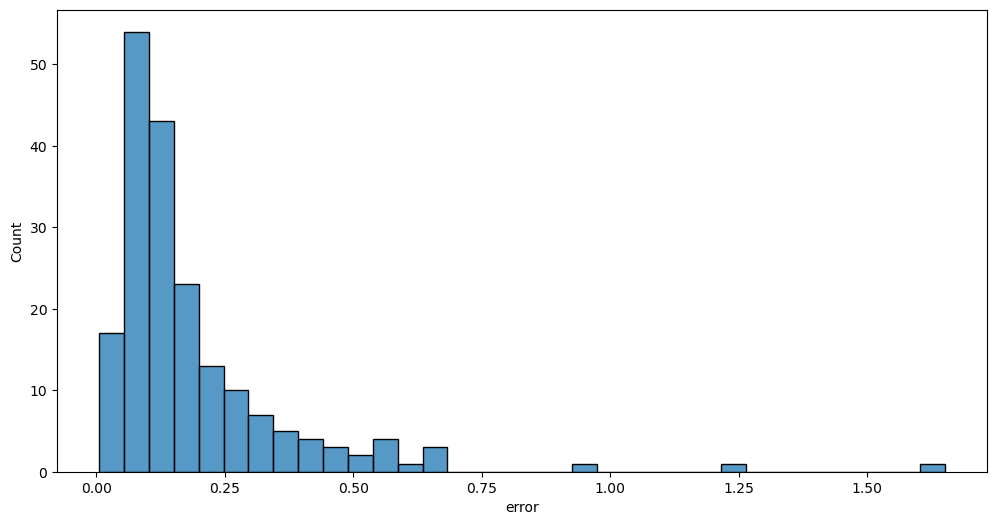

In [148]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(average_error["error"], ax=ax)
visible_ticks = [x_values[i] for i in range]
ax.set_xticks(visible_indices)
ax.set_xticklabels(visible_ticks, rotation=45, ha='right')  # Rotate and align the labels

